In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Retail_Sales_Data.csv")

df.head()

,OrderID,OrderDate,Product,Category,Region,Salesperson,Units,UnitPrice,Discount_pct,GrossSales,DiscountAmount,NetSales
0,ORD0001,2025-01-05,Laptop,Electronics,North,Amit,2,65000,5,130000,6500.0,123500.0
1,ORD0002,2025-01-12,Smartphone,Electronics,West,Priya,5,42000,10,210000,21000.0,189000.0
2,ORD0003,2025-01-19,Headphones,Accessories,South,Rahul,12,2500,8,30000,2400.0,27600.0
3,ORD0004,2025-01-26,Tablet,Electronics,East,Sneha,3,28000,5,84000,4200.0,79800.0
4,ORD0005,2025-02-02,Monitor,Electronics,North,Amit,4,18000,7,72000,5040.0,66960.0


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (20, 12)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   OrderID         20 non-null     str    
 1   OrderDate       20 non-null     str    
 2   Product         20 non-null     str    
 3   Category        20 non-null     str    
 4   Region          20 non-null     str    
 5   Salesperson     20 non-null     str    
 6   Units           20 non-null     int64  
 7   UnitPrice       20 non-null     int64  
 8   Discount_pct    20 non-null     int64  
 9   GrossSales      20 non-null     int64  
 10  DiscountAmount  20 non-null     float64
 11  NetSales        20 non-null     float64
dtypes: float64(2), int64(4), str(6)
memory usage: 2.9 KB


In [5]:
df.describe()

,Units,UnitPrice,Discount_pct,GrossSales,DiscountAmount,NetSales
count,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000
mean,8.000000,19772.500000,7.800000,78492.500000,5827.000000,72665.500000
std,6.680687,20154.883664,3.019237,67171.607166,5802.930385,61753.408725
min,1.000000,850.000000,3.000000,18000.000000,1350.000000,16200.000000
25%,3.750000,2650.000000,5.000000,29750.000000,2362.500000,26730.000000
50%,5.500000,13500.000000,7.500000,61500.000000,4260.000000,57730.000000
75%,10.500000,28500.000000,10.000000,101250.000000,5750.000000,95137.500000
max,25.000000,68000.000000,15.000000,280000.000000,22400.000000,257600.000000


In [6]:
df.columns

Index(['OrderID', 'OrderDate', 'Product', 'Category', 'Region', 'Salesperson',
       'Units', 'UnitPrice', 'Discount_pct', 'GrossSales', 'DiscountAmount',
       'NetSales'],
      dtype='str')

In [7]:
df.isnull().sum()

OrderID           0
OrderDate         0
Product           0
Category          0
Region            0
Salesperson       0
Units             0
UnitPrice         0
Discount_pct      0
GrossSales        0
DiscountAmount    0
NetSales          0
dtype: int64

In [8]:
df = df.dropna()

In [9]:
df["Region"].unique()

<ArrowStringArray>
['North', 'West', 'South', 'East']
Length: 4, dtype: str

In [10]:
df["Product"].unique()

<ArrowStringArray>
[      'Laptop',   'Smartphone',   'Headphones',       'Tablet',
      'Monitor',     'Keyboard',        'Mouse',   'Smartwatch',
      'Printer', 'Office Chair']
Length: 10, dtype: str

In [11]:
region_sales = df.groupby(
    "Region"
)["NetSales"].sum()

region_sales

Region
East     473410.0
North    277560.0
South    232280.0
West     470060.0
Name: NetSales, dtype: float64

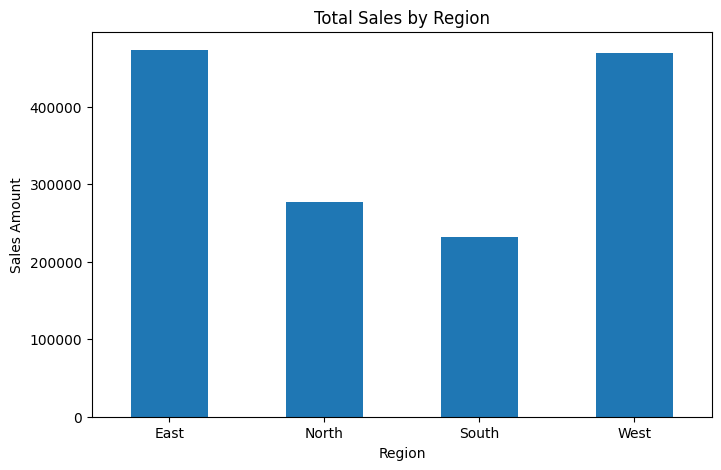

In [12]:
plt.figure(figsize=(8, 5))

region_sales.plot(
    kind="bar"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")

plt.xticks(rotation=0)

plt.show()

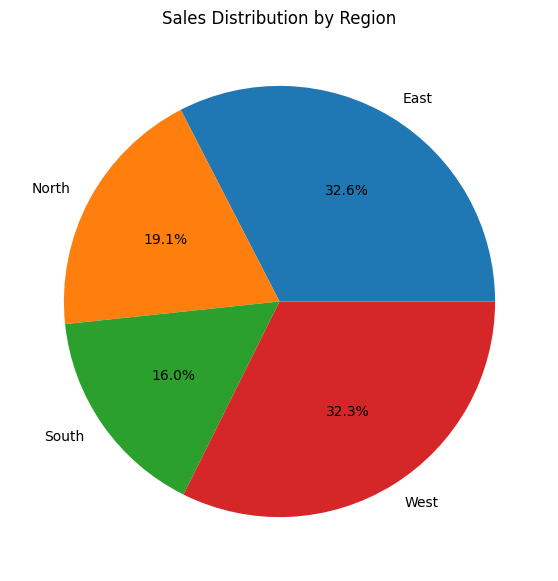

In [13]:
plt.figure(figsize=(7, 7))

region_sales.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Sales Distribution by Region")
plt.ylabel("")

plt.show()

In [14]:
top_regions = region_sales.sort_values(
    ascending=False
)

print(top_regions)

Region
East     473410.0
West     470060.0
North    277560.0
South    232280.0
Name: NetSales, dtype: float64


In [15]:
print(
    "Top Performing Region:",
    top_regions.index[0]
)

print(
    "Sales:",
    top_regions.iloc[0]
)

Top Performing Region: East
Sales: 473410.0


In [16]:
top_3 = top_regions.head(3)

print("Top 3 Regions:")
print(top_3)

Top 3 Regions:
Region
East     473410.0
West     470060.0
North    277560.0
Name: NetSales, dtype: float64


In [17]:
region_category_sales = df.groupby(
    ["Region", "Product"]
)["NetSales"].sum()

region_category_sales

Region  Product     
East    Keyboard         26010.0
        Office Chair     42320.0
        Smartphone      257600.0
        Smartwatch       67680.0
        Tablet           79800.0
North   Headphones       25650.0
        Laptop          123500.0
        Monitor          66960.0
        Mouse            18700.0
        Printer          42750.0
South   Headphones       27600.0
        Laptop           65960.0
        Monitor          95550.0
        Mouse            16200.0
        Printer          26970.0
West    Keyboard         23760.0
        Office Chair     49500.0
        Smartphone      189000.0
        Smartwatch       95000.0
        Tablet          112800.0
Name: NetSales, dtype: float64

In [18]:
region_category_table = df.pivot_table(
    values="NetSales",
    index="Region",
    columns="Product",
    aggfunc="sum"
)

region_category_table

Product,Headphones,Keyboard,Laptop,Monitor,Mouse,Office Chair,Printer,Smartphone,Smartwatch,Tablet
Region,,,,,,,,,,
East,NaN,26010.0,NaN,NaN,NaN,42320.0,NaN,257600.0,67680.0,79800.0
North,25650.0,NaN,123500.0,66960.0,18700.0,NaN,42750.0,NaN,NaN,NaN
South,27600.0,NaN,65960.0,95550.0,16200.0,NaN,26970.0,NaN,NaN,NaN
West,NaN,23760.0,NaN,NaN,NaN,49500.0,NaN,189000.0,95000.0,112800.0


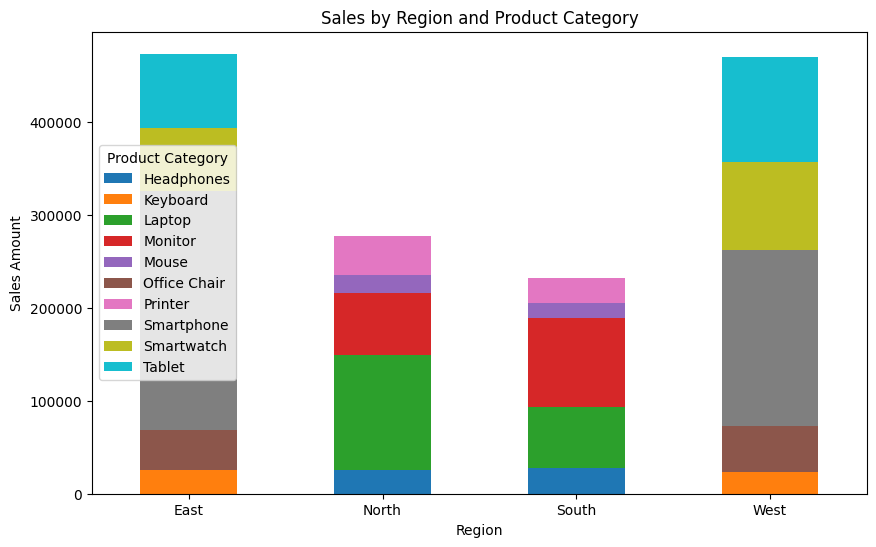

In [19]:
region_category_table.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title(
    "Sales by Region and Product Category"
)

plt.xlabel("Region")
plt.ylabel("Sales Amount")

plt.xticks(rotation=0)

plt.legend(
    title="Product Category"
)

plt.show()

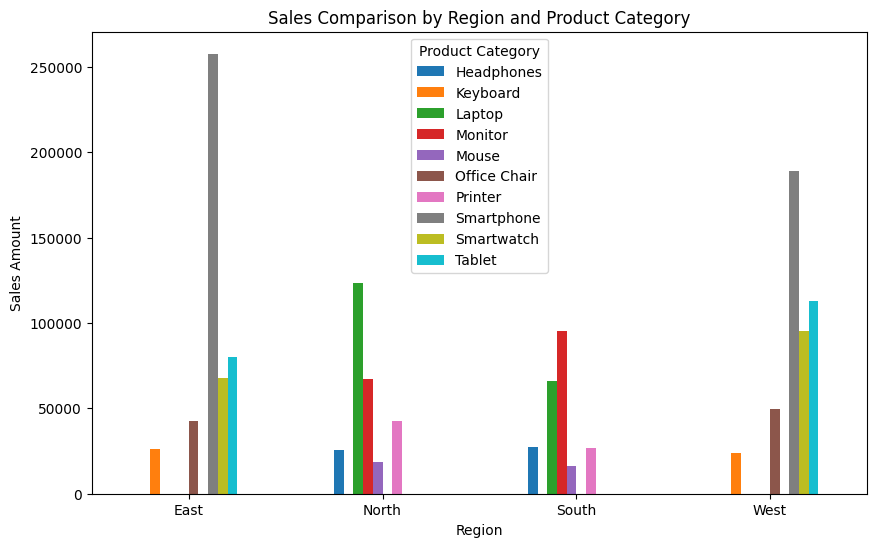

In [20]:
region_category_table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Sales Comparison by Region and Product Category"
)

plt.xlabel("Region")
plt.ylabel("Sales Amount")

plt.xticks(rotation=0)

plt.legend(
    title="Product Category"
)

plt.show()

In [21]:
region_quantity = df.groupby(
    "Region"
)["Units"].sum()

print(region_quantity)

Region
East     38
North    44
South    41
West     37
Name: Units, dtype: int64


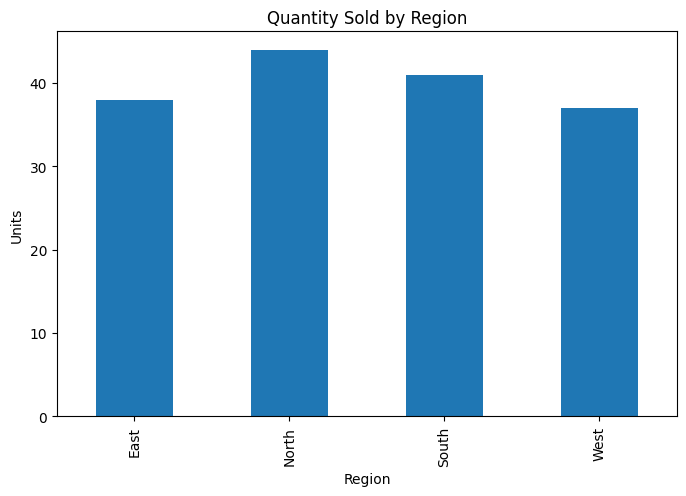

In [22]:
region_quantity.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Quantity Sold by Region")
plt.xlabel("Region")
plt.ylabel("Units")

plt.show()